# **Minería de Textos — Clasificación de textos gastronómicos en Esperanto**

**Integrantes:** María Moreno, Adriana Díaz y Sofía Pérez
**Temática:** Gastronomía · **Categorías:** `comida`, `bebida`, `postre`

Este cuaderno reúne la ejecución y los resultados de la **Fase 3**. Las Fases 1 y 2 se implementan en el repositorio (arquitectura opcional del apartado 9.1 del enunciado v2). Desde Colab descarga la librería y el dataset de GitHub. El equipo debe publicar previamente el repositorio, generar el dataset real y crear la etiqueta de versión.

**Importante:** no se presenta ningún resultado de un dataset de prueba como si fuera un resultado real de la práctica.

| Fase | Dónde está |
|---|---|
| 1. Dataset (`text;class`) y script que lo genera | Repositorio: `scripts/build_dataset.py`, `data/` |
| 2. Librería `eonlp` (tokenizador, lematizador, POS, stopwords, Doc/Token) con tests y documentación | Repositorio: `src/eonlp/`, `tests/`, `docs/` |
| 3. Entrenamiento, evaluación y clasificación de páginas web | **Este cuaderno** |

**Índice**

0. Configuración e instalación
1. La librería `eonlp`
2. Carga y exploración del dataset
3. Preparación de los textos con `eonlp`
4. Partición en entrenamiento y prueba (por artículos)
5. ¿Qué preparación del texto funciona mejor?
6. Representación tabular del corpus (TF-IDF)
7. Comparación de modelos
8. Ajuste de hiperparámetros
9. Evaluación final
10. Análisis del modelo
11. Clasificación de páginas web
12. Conclusiones

## **0. Configuración e instalación**

Todos los parámetros están en esta celda.

- `VERSION` es una etiqueta (*tag*) del repositorio. Fija a la vez la versión de la librería y la del dataset, así los resultados se pueden reproducir.
- **Independencia de temática:** para entrenar con el dataset de otro equipo basta con poner la URL de su CSV en `DATASET_URL`. Tiene que cumplir el contrato de datos (`text;class`). El resto del cuaderno no depende de las clases concretas.
- `REGENERAR_DATASET = True` permite ejecutar la generación de la Fase 1 desde el cuaderno usando el script versionado del repositorio. Por defecto usa el CSV ya publicado, para que el entrenamiento sea rápido.
- Si se usan datos de otra temática, es conveniente aportar su CSV de metadatos para dividir por artículos.


In [1]:
# ===================== CONFIGURACIÓN =====================
GITHUB_USUARIO = "mariamorenocaso"         # usuario u organización de GitHub
GITHUB_REPO = "eonlp-gastronomia"         # nombre del repositorio
VERSION = "v1.0.0"                  # etiqueta del repositorio (librería + dataset). Versión del proyecto

# Dataset. None = el de nuestro repositorio. Para usar otro, poner la URL de un CSV text;class.
DATASET_URL = None
# Opcional: CSV text;class;article para separar entrenamiento y prueba por artículos.
META_URL = None

SEMILLA = 42                        # semilla única para todo el cuaderno
TAMANO_PRUEBA = 0.2                 # 20 % de los datos para la prueba final
N_PARTES_CV = 5                     # partes de la validación cruzada
REGENERAR_DATASET = False           # Evita volver a descargar todos los artículos de Wikipedia


In [2]:
# Instalamos desde la versión FIJA del repositorio; no se cambia a main de forma silenciosa.
# El modelo y el CSV deben proceder de la misma versión para asegurar reproducibilidad.
import subprocess
import sys

if GITHUB_USUARIO == "USUARIO" or GITHUB_REPO == "REPOSITORIO":
    raise ValueError("Primero publica el repositorio y sustituye GITHUB_USUARIO y GITHUB_REPO en la celda 0.")

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       f"git+https://github.com/{GITHUB_USUARIO}/{GITHUB_REPO}.git@{VERSION}"])


0

In [3]:
# Si falla la instalación, se detiene. Una versión alternativa podría dar métricas
# distintas e invalidar la reproducibilidad.
import eonlp
print("Librería instalada correctamente:", eonlp.__version__)


Librería instalada correctamente: 1.0.0


In [4]:
import io, json, random, sys, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import sklearn
from bs4 import BeautifulSoup
from IPython.display import display, Markdown

from sklearn.model_selection import (train_test_split, StratifiedKFold, StratifiedGroupKFold,
                                     cross_validate, cross_val_predict, GridSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings("ignore", category=FutureWarning)

# Reproducibilidad: la misma semilla en todas las fuentes de azar
random.seed(SEMILLA)
np.random.seed(SEMILLA)

inicio_cuaderno = time.time()
print(f"Python {sys.version.split()[0]} | eonlp {eonlp.__version__} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")

Python 3.13.18 | eonlp 1.0.0 | scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6


## **1. La librería `eonlp`**

`eonlp` es nuestra librería de NLP para Esperanto. Está hecha desde cero, sin spaCy ni NLTK, y se basa en reglas. Su interfaz imita la de spaCy: `nlp = eonlp.load()` y `doc = nlp(texto)`.

- **Tokenizador:** palabras, números, compuestos con guion, elisión (`l'`) y sistema-x (`cx` → `ĉ`).
- **Lematizador:** usa la terminación (`kukojn` → `kuko`, `manĝis` → `manĝi`, `kuirita` → `kuiri`).
- **Etiquetador POS** con etiquetas de Universal Dependencies y **rasgos morfológicos** (caso, número, tiempo, modo, voz).
- **Raíces:** quita prefijos y sufijos derivativos (`kuketo` → `kuk`, `kafejo` → `kaf`).
- **Stopwords:** lista cerrada (preposiciones, conjunciones, pronombres, correlativos...) que se puede ampliar.

Ejemplo:

In [5]:
nlp = eonlp.load()

doc = nlp("La kuiristo bakis ĉokoladajn kukojn kaj kuketojn. Ĉu vi trinkos kafon aŭ teon?")
#Traducción: El cocinero horneó pasteles de chocolate y galletas. ¿Beberás café o té?
display(pd.DataFrame([t.to_dict() for t in doc]).drop(columns=["i", "is_punct"]))

print("Frases:", [s.text for s in doc.sents])
print("Palabras para el clasificador (lemas sin stopwords):", doc.words())
print("Número de stopwords:", len(nlp.stop_words))

,text,lemma,pos,morph,root,is_stop,is_sent_start
0,La,la,DET,PronType=Art,la,True,True
1,kuiristo,kuiristo,NOUN,Case=Nom|Number=Sing,kuir,False,False
2,bakis,baki,VERB,Mood=Ind|Tense=Past|VerbForm=Fin,bak,False,False
3,ĉokoladajn,ĉokolada,ADJ,Case=Acc|Number=Plur,ĉokolad,False,False
4,kukojn,kuko,NOUN,Case=Acc|Number=Plur,kuk,False,False
5,kaj,kaj,CCONJ,,kaj,True,False
6,kuketojn,kuketo,NOUN,Case=Acc|Number=Plur,kuk,False,False
7,.,.,PUNCT,,.,False,False
8,Ĉu,ĉu,PART,,ĉu,True,True
9,vi,vi,PRON,Case=Nom|PronType=Prs,vi,True,False


Frases: ['La kuiristo bakis ĉokoladajn kukojn kaj kuketojn.', 'Ĉu vi trinkos kafon aŭ teon?']
Palabras para el clasificador (lemas sin stopwords): ['kuiristo', 'baki', 'ĉokolada', 'kuko', 'kuketo', 'trinki', 'kafo', 'teo']
Número de stopwords: 266


¿Qué significa cada columna?

Columna	Significado	Ejemplo de tu tabla
text	Palabra original	kukojn
lemma	Forma básica de la palabra	kuko
pos	Categoría gramatical	NOUN (sustantivo)
morph	Características gramaticales	Plural y acusativo
root	Raíz de la palabra	kuk
is_stop	Si es una stopword	True o False
is_sent_start	Si comienza una frase	True o False NO SE COMO PONERLO BONITO

## **2. Carga, generación opcional y exploración del dataset**

La Fase 1 está implementada en `scripts/build_dataset.py`, que usa la API de Vikipedio, separa artículos en párrafos, filtra ruido y escribe `dataset.csv` (`text;class`) y `dataset_meta.csv` (incluye `article`).

**Para reproducir la generación dentro de Colab:** establecer `REGENERAR_DATASET = True` en la celda de configuración. El cuaderno descarga el código fuente y el JSON desde la versión fijada de GitHub, ejecuta la generación y carga esos CSV. Es más lento que descargar el dataset ya generado.

**Para ejecutar rápido:** dejar `REGENERAR_DATASET = False`. Se descarga el dataset ya publicado. Si el repositorio aún no contiene los CSV, el cuaderno se detiene explicando cómo crearlos; **no inventa textos ni resultados de entrenamiento**.

Se usa `dataset_meta.csv` para impedir que los párrafos del mismo artículo estén a ambos lados de la partición train/test.


In [6]:
def urls_repo(ruta):
    # Direcciones alternativas para un fichero del repositorio
    return [
        f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{GITHUB_REPO}/{VERSION}/{ruta}",
        f"https://cdn.jsdelivr.net/gh/{GITHUB_USUARIO}/{GITHUB_REPO}@{VERSION}/{ruta}",
    ]


def descargar_texto(urls, timeout=20):
    # Prueba cada dirección hasta que una funciona. Devuelve None si fallan todas.
    for url in urls:
        try:
            if not url.startswith("http"):                       # también acepta rutas locales
                with open(url, encoding="utf-8") as f:
                    return f.read()
            r = requests.get(url, timeout=timeout)
            r.raise_for_status()
            r.encoding = "utf-8"
            return r.text
        except Exception as error:
            print(f"   No disponible: {url} ({type(error).__name__})")
    return None


def leer_csv(urls):
    texto = descargar_texto(urls)
    if texto is None:
        return None
    return pd.read_csv(io.StringIO(texto), sep=";", dtype=str, keep_default_na=False)


def validar_contrato(datos):
    # Comprueba el contrato de datos y limpia el dataset
    assert list(datos.columns[:2]) == ["text", "class"], f"Columnas incorrectas: {list(datos.columns)}"
    datos = datos[["text", "class"]].copy()
    datos["text"] = datos["text"].str.strip()
    datos["class"] = datos["class"].str.strip().str.lower()
    n0 = len(datos)
    datos = datos[(datos["text"] != "") & (datos["class"] != "")]
    contradictorios = datos.groupby("text")["class"].nunique()
    datos = datos[~datos["text"].isin(contradictorios[contradictorios > 1].index)]
    datos = datos.drop_duplicates("text").reset_index(drop=True)
    assert datos["class"].nunique() >= 2, "El dataset necesita al menos 2 clases"
    print(f"Contrato de datos correcto. Filas: {n0} -> {len(datos)} tras quitar vacías, duplicadas y contradictorias.")
    return datos


# Generación opcional de la Fase 1, invocada desde el cuaderno y sin rutas locales previas.
# El script versionado es la fuente de verdad: no duplicamos su lógica en dos lugares.
if REGENERAR_DATASET:
    import tempfile
    from pathlib import Path
    codigo = descargar_texto(urls_repo("scripts/build_dataset.py"))
    configuracion = descargar_texto(urls_repo("config/gastronomio.json"))
    if not codigo or not configuracion:
        raise RuntimeError("No se ha podido recuperar el generador de la Fase 1 desde GitHub.")
    carpeta_temp = tempfile.TemporaryDirectory()
    raiz_temp = Path(carpeta_temp.name)
    (raiz_temp / "build_dataset.py").write_text(codigo, encoding="utf-8")
    (raiz_temp / "gastronomio.json").write_text(configuracion, encoding="utf-8")
    subprocess.check_call([sys.executable, str(raiz_temp / "build_dataset.py"),
                           "--config", str(raiz_temp / "gastronomio.json"),
                           "--out", str(raiz_temp)])
    df = leer_csv([str(raiz_temp / "dataset.csv")])
    meta = leer_csv([str(raiz_temp / "dataset_meta.csv")])
else:
    df = leer_csv([DATASET_URL] if DATASET_URL else urls_repo("data/dataset.csv"))
    # Metadatos opcionales: artículo de origen de cada párrafo
    meta = leer_csv([META_URL] if META_URL else ([] if DATASET_URL else urls_repo("data/dataset_meta.csv")))

if df is None:
    raise RuntimeError("No hay un dataset real accesible. Ejecuta scripts/build_dataset.py y publica "
                       "los CSV en GitHub, o activa REGENERAR_DATASET = True. "
                       "Comprueba GITHUB_USUARIO, GITHUB_REPO y VERSION.")
df = validar_contrato(df)
if meta is not None and "article" in meta.columns:
    articulo_de = dict(zip(meta["text"].str.strip(), meta["article"]))
    df["article"] = [articulo_de.get(t, f"__sin_articulo_{i}") for i, t in enumerate(df["text"])]
    print(f"Metadatos cargados: {df['article'].nunique()} artículos de origen.")
else:
    df["article"] = None
    print("Sin metadatos de artículo: la partición se hará por párrafos.")

CLASES = sorted(df["class"].unique())
paleta = plt.get_cmap("tab10")
COLORES = {c: paleta(i) for i, c in enumerate(CLASES)}
print("Clases:", CLASES)
display(df.sample(min(5, len(df)), random_state=SEMILLA)[["text", "class"]])
if (df["class"].value_counts() < 300).any():
    print("AVISO: hay clases con menos de 300 párrafos reales. El enunciado lo recomienda como orientación, no exige un mínimo.")

Contrato de datos correcto. Filas: 3152 -> 3152 tras quitar vacías, duplicadas y contradictorias.
Metadatos cargados: 548 artículos de origen.
Clases: ['bebida', 'comida', 'postre']


,text,class
3142,La dolĉaĵoj nuntempe ekzistas en pluraj malsam...,postre
1840,Ostrofungo aŭ ostra pleŭroto (Pleurotus ostrea...,comida
2359,"bolŝinko, ĝi post la peklado estas traktata en...",comida
2602,Gustumo de japanaj dolĉaĵoj estas tuta arto ka...,postre
2998,"""Oyoge! Taiyaki-kun"" (litere, ""Naĝu! Taiyaki"")...",postre


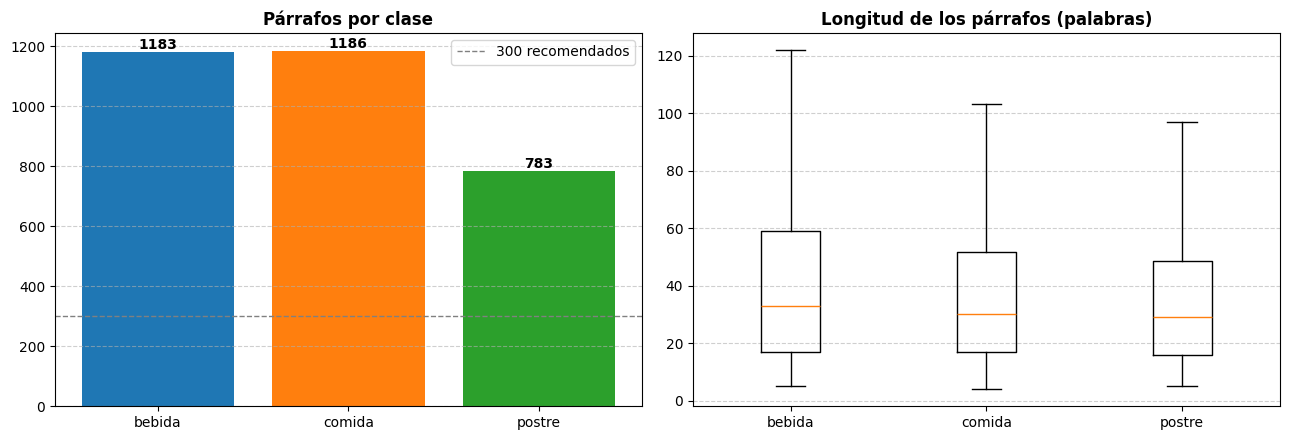

,count,mean,50%,min,max
class,,,,,
bebida,1183.0,43.0,33.0,5.0,281.0
comida,1186.0,38.3,30.0,4.0,231.0
postre,783.0,36.8,29.0,5.0,247.0


In [7]:
# Número de párrafos y longitud (en palabras) por clase
df["n_palabras"] = df["text"].str.split().str.len()
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

conteo = df["class"].value_counts().reindex(CLASES)
barras = ejes[0].bar(CLASES, conteo.values, color=[COLORES[c] for c in CLASES])
ejes[0].bar_label(barras, fontweight="bold")
ejes[0].axhline(300, color="gray", linestyle="--", linewidth=1, label="300 recomendados")
ejes[0].set_title("Párrafos por clase", fontweight="bold")
ejes[0].legend()

ejes[1].boxplot([df.loc[df["class"] == c, "n_palabras"] for c in CLASES], showfliers=False)
ejes[1].set_xticks(range(1, len(CLASES) + 1), CLASES)
ejes[1].set_title("Longitud de los párrafos (palabras)", fontweight="bold")
for eje in ejes:
    eje.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

display(df.groupby("class")["n_palabras"].describe()[["count", "mean", "50%", "min", "max"]].round(1))

**Ruido en la construcción del dataset.** Cada párrafo hereda la etiqueta de su artículo, y eso introduce ruido: hay párrafos genéricos, como *"Ĝi estis fondita en 1950"*, que no distinguen ninguna clase. El script de la Fase 1 ya descarta títulos, párrafos cortos, secciones finales (*Referencoj*, *Vidu ankaŭ*...), párrafos que la librería no reconoce como Esperanto, duplicados y párrafos con etiquetas contradictorias. Guarda los recuentos en `noise_report.json`. El ruido que queda se mide con el modelo en el apartado 10.5.

In [8]:
informe_ruido = None
if not DATASET_URL:
    texto = descargar_texto(urls_repo("data/noise_report.json"))
    informe_ruido = json.loads(texto) if texto else None

if informe_ruido:
    descartes = pd.Series(informe_ruido["discarded_paragraphs"]).sort_values(ascending=False)
    total = informe_ruido["paragraphs_kept"] + descartes.sum()
    print(f"Párrafos conservados: {informe_ruido['paragraphs_kept']} de {total} "
          f"({informe_ruido['paragraphs_kept'] / total:.0%})")
    display(descartes.rename("párrafos descartados").to_frame())
    print("Selección de artículos:", informe_ruido.get("article_selection"))
else:
    print("No hay informe de ruido disponible (se continúa sin él).")

Párrafos conservados: 3152 de 5364 (59%)


,párrafos descartados
titulo,889
corto,840
seccion_final,388
no_esperanto,91
duplicado,2
etiqueta_contradictoria,2


Selección de artículos: {'ambiguous': 62, 'reserved': 11, 'lists': 11}


Interpretación de los resultados
Inicialmente teníamos 5.364 fragmentos de texto candidatos, pero no todos eran útiles para entrenar el modelo.

Esto es lo que llamamos limpieza del dataset.

También hemos excluido artículos ambiguos, artículos reservados para pruebas y artículos que son listas.

⚠️ Aunque hemos realizado esta limpieza, todavía pueden quedar párrafos que no estén correctamente relacionados con su categoría. Eso es lo que llamamos ruido semántico.

## **3. Preparación de los textos con `eonlp`**

Cada párrafo se analiza **una sola vez** con nuestra librería. A partir de ese análisis se generan cuatro versiones del texto, que se comparan en el apartado 5:

| Versión | Qué se hace | Ejemplo con *"kuketojn"* |
|---|---|---|
| A) Texto original | nada (referencia, sin nuestra librería) | `kuketojn` |
| B) Palabras | minúsculas, sin stopwords ni puntuación | `kuketojn` |
| C) Lemas | como B, pero con el lema | `kuketo` |
| D) Raíces | como B, pero con la raíz | `kuk` |

En B, C y D se quitan las palabras de menos de 2 letras y los números; A conserva el texto original sin procesar. Se usa `Doc.words()`, el método de la librería pensado para esto.

In [9]:
inicio = time.time()
docs = list(nlp.pipe(df["text"]))
print(f"{len(docs)} párrafos analizados en {time.time() - inicio:.1f} s")

ATRIBUTOS = {"B) Palabras sin stopwords": "lower_", "C) Lemas sin stopwords": "lemma_", "D) Raíces sin stopwords": "root_"}
VERSIONES = {"A) Texto original (sin eonlp)": df["text"].tolist()}
for nombre, atributo in ATRIBUTOS.items():
    VERSIONES[nombre] = [" ".join(d.words(atributo, min_len=2, alpha_only=True)) for d in docs]

y = df["class"].to_numpy()
grupos = df["article"].to_numpy() if df["article"].notna().all() else None

antes = np.mean([len(d) for d in docs])
despues = np.mean([len(t.split()) for t in VERSIONES["C) Lemas sin stopwords"]])
print(f"Tokens por párrafo: {antes:.1f} antes -> {despues:.1f} palabras útiles después")

ejemplo = pd.DataFrame({"original": df["text"].str[:90] + "..."})
for nombre in ATRIBUTOS:
    ejemplo[nombre[:2]] = [t[:70] + "..." for t in VERSIONES[nombre]]
display(ejemplo.head(3))

3152 párrafos analizados en 2.2 s
Tokens por párrafo: 47.4 antes -> 22.3 palabras útiles después


,original,B),C),D)
0,55 Bar (esperante: trinkejo 55) estas ĵaza klu...,bar esperante trinkejo ĵaza klubo novjorka urb...,bar esperi trinkejo ĵaza klubo novjorka urbo g...,bar esper trink ĵaz klub novjork urb greenwich...
1,"20 %, por elteni faŭnon kaj flaŭron, por la tr...",elteni faŭnon flaŭron transporto havaĵoj ŝipoj...,elteni faŭno flaŭro transporto havaĵo ŝipo fiŝ...,elten faŭn flaŭr transport hav ŝip fiŝkapt...
2,Administroj de akvo en agrikulturo malsamas ek...,administroj akvo agrikulturo malsamas ekonomie...,administro akvo agrikulturo malsami ekonomie s...,administr akv agrikultur sam ekonomi soci regi...


## **4. Partición en entrenamiento y prueba (por artículos)**

Los párrafos de un mismo artículo comparten vocabulario muy concreto: el nombre del plato, sus ingredientes... Si se reparten al azar, el modelo ve en entrenamiento párrafos "hermanos" de los de prueba y la nota sale **optimista**.

Para evitarlo, cuando hay metadatos se usa una partición **por grupos**: todos los párrafos de un artículo van juntos a entrenamiento o a prueba (`StratifiedGroupKFold`, que además mantiene la proporción de clases). Si el dataset no trae metadatos (por ejemplo, el de otro equipo), se usa una partición estratificada normal.

- **Entrenamiento (≈80 %):** para aprender, comparar modelos y ajustar parámetros con validación cruzada (también por grupos).
- **Prueba (≈20 %):** no se toca hasta la evaluación final.

In [10]:
indices = np.arange(len(df))

if grupos is not None:
    particion = StratifiedGroupKFold(n_splits=round(1 / TAMANO_PRUEBA), shuffle=True, random_state=SEMILLA)
    idx_train, idx_test = next(particion.split(indices, y, groups=grupos))
    cv = StratifiedGroupKFold(n_splits=N_PARTES_CV, shuffle=True, random_state=SEMILLA)
    g_train = grupos[idx_train]
    comunes = set(grupos[idx_train]) & set(grupos[idx_test])
    print(f"Partición por artículos: {len(set(g_train))} artículos en entrenamiento, "
          f"{len(set(grupos[idx_test]))} en prueba, {len(comunes)} compartidos.")
else:
    idx_train, idx_test = train_test_split(indices, test_size=TAMANO_PRUEBA, stratify=y, random_state=SEMILLA)
    cv = StratifiedKFold(n_splits=N_PARTES_CV, shuffle=True, random_state=SEMILLA)
    g_train = None
    print("Partición estratificada por párrafos.")

y_train, y_test = y[idx_train], y[idx_test]
if set(y_train) != set(CLASES) or set(y_test) != set(CLASES):
    raise RuntimeError("La partición deja alguna clase sin ejemplos en train o test. "
                       "Aumenta los artículos por clase o revisa las agrupaciones.")
if grupos is not None:
    assert not (set(grupos[idx_train]) & set(grupos[idx_test])), "Fuga de artículos train/test"
reparto = pd.DataFrame({"entrenamiento": pd.Series(y_train).value_counts(),
                        "prueba": pd.Series(y_test).value_counts()}).reindex(CLASES)
reparto["% en prueba"] = (reparto["prueba"] / reparto.sum(axis=1) * 100).round(1)
print(f"Entrenamiento: {len(idx_train)} párrafos | Prueba: {len(idx_test)} párrafos")
display(reparto)


def cv_args():
    # Argumentos comunes para validar siempre igual (con grupos si los hay)
    return {"cv": cv, "groups": g_train}

Partición por artículos: 439 artículos en entrenamiento, 109 en prueba, 0 compartidos.
Entrenamiento: 2497 párrafos | Prueba: 655 párrafos


,entrenamiento,prueba,% en prueba
bebida,868,315,26.6
comida,1016,170,14.3
postre,613,170,21.7


## **5. ¿Qué preparación del texto funciona mejor?**

Antes de elegir modelo comprobamos si nuestra librería ayuda de verdad. Se compara cada versión del texto con el mismo vectorizador (TF-IDF) y el mismo clasificador (regresión logística), con validación cruzada **solo sobre el entrenamiento**.

La métrica principal es el **F1 macro**: la media del F1 de cada clase. Cuenta igual una clase pequeña que una grande, mientras que la accuracy puede engañar si las clases están desequilibradas.

El vectorizador va dentro de un `Pipeline`, así que en cada parte de la validación se vuelve a ajustar solo con los datos de entrenamiento de esa parte. De este modo no hay fuga de información.

,Accuracy,F1 macro,Desv. F1,Vocabulario
Versión,,,,
A) Texto original (sin eonlp),0.698,0.679,0.025,7017
B) Palabras sin stopwords,0.714,0.698,0.017,6471
C) Lemas sin stopwords,0.744,0.730,0.019,5183
D) Raíces sin stopwords,0.747,0.732,0.017,4014


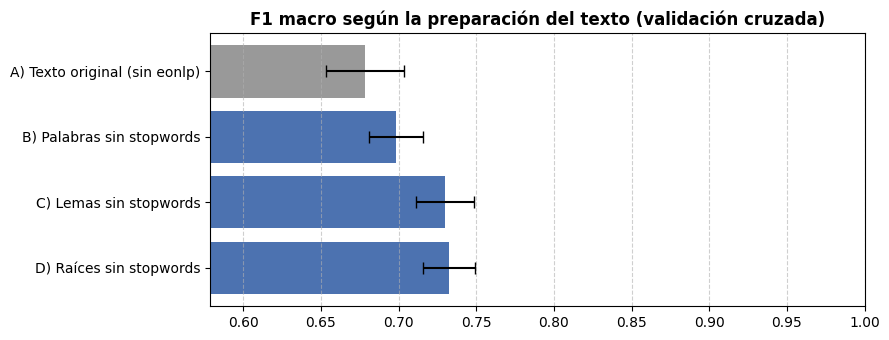

Versión elegida: D) Raíces sin stopwords (+0.054 de F1 macro respecto al texto original)


In [11]:
PARAMS_TFIDF = dict(min_df=2, sublinear_tf=True, token_pattern=r"\S+")
clasificador_ref = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMILLA)

filas = []
for nombre, textos in VERSIONES.items():
    params = dict(min_df=2, sublinear_tf=True) if nombre.startswith("A") else PARAMS_TFIDF
    X_v = [textos[i] for i in idx_train]
    tuberia = Pipeline([("tfidf", TfidfVectorizer(**params)), ("clf", clasificador_ref)])
    r = cross_validate(tuberia, X_v, y_train, scoring=["accuracy", "f1_macro"], **cv_args())
    filas.append({"Versión": nombre, "Accuracy": r["test_accuracy"].mean(), "F1 macro": r["test_f1_macro"].mean(),
                  "Desv. F1": r["test_f1_macro"].std(),
                  "Vocabulario": len(TfidfVectorizer(**params).fit(X_v).vocabulary_)})

tabla_prep = pd.DataFrame(filas).set_index("Versión")
display(tabla_prep.round(3))

plt.figure(figsize=(9, 3.5))
plt.barh(tabla_prep.index, tabla_prep["F1 macro"], xerr=tabla_prep["Desv. F1"], capsize=4,
         color=["#999999"] + ["#4C72B0"] * (len(tabla_prep) - 1))
plt.xlim(max(0, tabla_prep["F1 macro"].min() - 0.1), 1)
plt.gca().invert_yaxis()
plt.title("F1 macro según la preparación del texto (validación cruzada)", fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Se elige entre las versiones que usan nuestra librería (B, C, D). A es solo la referencia.
VERSION_ELEGIDA = tabla_prep.drop(index=tabla_prep.index[0])["F1 macro"].idxmax()
mejora = tabla_prep.loc[VERSION_ELEGIDA, "F1 macro"] - tabla_prep.iloc[0]["F1 macro"]
print(f"Versión elegida: {VERSION_ELEGIDA} ({mejora:+.3f} de F1 macro respecto al texto original)")

¿Cuál elegimos?
Elegimos la opción D: raíces sin stopwords, porque obtiene el mayor F1 macro medio.

Además, conseguimos reducir el vocabulario de 7.017 a 4.014 términos.

La mejora del F1 macro respecto al texto original es de aproximadamente 5,4 puntos porcentuales, según el cálculo del cuaderno.

⚠️ La diferencia entre C y D es muy pequeña y sus barras de error se solapan. Por tanto, no podemos afirmar que D sea significativamente mejor que C.

**Cómo leerlo:** la barra de error es la desviación entre las partes de la validación. Si dos versiones se solapan, la diferencia no es muy fiable. Los lemas y las raíces pueden reducir el vocabulario, al agrupar algunas formas de una misma palabra; comprobamos el efecto en la tabla anterior. Con pocos datos, eso suele ayudar al modelo a generalizar.

## **6. Representación tabular del corpus (matriz TF-IDF)**

Con la versión elegida se construye la tabla con la que aprende el modelo: **una fila por párrafo y una columna por palabra**.

- **TF:** frecuencia de la palabra en el párrafo. Con `sublinear_tf` se usa `1 + log(tf)`, para que una palabra repetida 10 veces no pese 10 veces más.
- **IDF:** baja el peso de las palabras que aparecen en muchos párrafos.
- `min_df=2`: se ignoran las palabras que salen en un solo párrafo.

El vocabulario se aprende **solo con el entrenamiento**. La matriz es dispersa: casi todos sus valores son 0.

In [12]:
textos_finales = VERSIONES[VERSION_ELEGIDA]
X_train = [textos_finales[i] for i in idx_train]
X_test = [textos_finales[i] for i in idx_test]

vectorizador = TfidfVectorizer(**PARAMS_TFIDF)
M_train = vectorizador.fit_transform(X_train)
M_test = vectorizador.transform(X_test)
vocabulario = vectorizador.get_feature_names_out()

print(f"Entrenamiento: {M_train.shape[0]} párrafos x {M_train.shape[1]} palabras")
print(f"Prueba:        {M_test.shape[0]} párrafos x {M_test.shape[1]} palabras")
print(f"Celdas distintas de cero: {M_train.nnz / np.prod(M_train.shape):.2%}")

frecuentes = np.asarray((M_train > 0).sum(axis=0)).ravel().argsort()[::-1][:8]
muestra = pd.DataFrame(M_train[:5, frecuentes].toarray(), columns=vocabulario[frecuentes]).round(3)
muestra.insert(0, "clase", y_train[:5])
print("\nEjemplo: 5 párrafos x las 8 palabras más repartidas")
display(muestra)

Entrenamiento: 2497 párrafos x 4014 palabras
Prueba:        655 párrafos x 4014 palabras
Celdas distintas de cero: 0.42%

Ejemplo: 5 párrafos x las 8 palabras más repartidas


,clase,far,nom,manĝ,produkt,ali,oft,frukt,grand
0,bebida,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,bebida,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,bebida,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,bebida,0.086,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,bebida,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## **7. Comparación de modelos**

Se prueban varios algoritmos ligeros, adecuados para texto y rápidos en Colab sin GPU, todos con la misma validación cruzada:

- **Baseline:** responde siempre la clase más frecuente. Es el mínimo que hay que superar.
- **Naive Bayes multinomial** y **Complement NB:** modelos probabilísticos. CNB suele ir mejor con clases desequilibradas.
- **Regresión logística:** aprende un peso por palabra y clase.
- **SVM lineal (calibrada):** la calibración permite obtener probabilidades, que hacen falta para clasificar páginas web.

`class_weight="balanced"` da más peso a los errores en las clases pequeñas.

,Accuracy,F1 macro,Desv. F1,Tiempo (s)
Modelo,,,,
Regresión logística,0.747,0.732,0.017,0.826
SVM lineal (calibrada),0.733,0.717,0.015,0.589
Complement Naive Bayes,0.729,0.715,0.024,0.085
Naive Bayes multinomial,0.703,0.674,0.022,0.063
Baseline (clase más frecuente),0.409,0.193,0.008,0.092


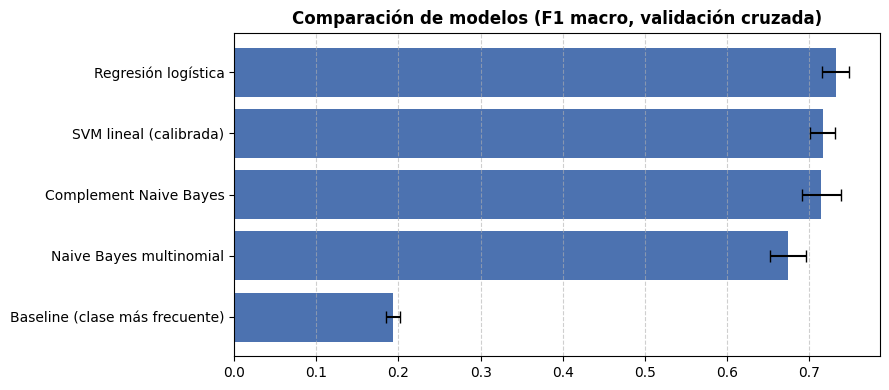

Mejor modelo: Regresión logística


In [13]:
MODELOS = {
    "Baseline (clase más frecuente)": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes multinomial": MultinomialNB(),
    "Complement Naive Bayes": ComplementNB(),
    "Regresión logística": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMILLA),
    "SVM lineal (calibrada)": CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=SEMILLA), cv=3),
}

inicio_entrenamiento = time.time()
filas = []
for nombre, modelo in MODELOS.items():
    tuberia = Pipeline([("tfidf", TfidfVectorizer(**PARAMS_TFIDF)), ("clf", modelo)])
    r = cross_validate(tuberia, X_train, y_train, scoring=["accuracy", "f1_macro"], **cv_args())
    filas.append({"Modelo": nombre, "Accuracy": r["test_accuracy"].mean(), "F1 macro": r["test_f1_macro"].mean(),
                  "Desv. F1": r["test_f1_macro"].std(), "Tiempo (s)": r["fit_time"].mean()})

tabla_modelos = pd.DataFrame(filas).set_index("Modelo").sort_values("F1 macro", ascending=False)
display(tabla_modelos.round(3))

plt.figure(figsize=(9, 4))
plt.barh(tabla_modelos.index, tabla_modelos["F1 macro"], xerr=tabla_modelos["Desv. F1"], capsize=4, color="#4C72B0")
plt.gca().invert_yaxis()
plt.title("Comparación de modelos (F1 macro, validación cruzada)", fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

MEJOR = tabla_modelos.drop(index="Baseline (clase más frecuente)")["F1 macro"].idxmax()
print("Mejor modelo:", MEJOR)

## **8. Ajuste de hiperparámetros**

Con `GridSearchCV` se prueban combinaciones de parámetros del vectorizador (palabras sueltas o también pares de palabras, frecuencia mínima) y del clasificador. Cada combinación se puntúa con F1 macro en validación cruzada (por grupos). Se hace solo con el entrenamiento.

In [14]:
REJILLAS = {
    "Naive Bayes multinomial": {"clf__alpha": [0.05, 0.1, 0.3, 1.0]},
    "Complement Naive Bayes": {"clf__alpha": [0.05, 0.1, 0.3, 1.0]},
    "Regresión logística": {"clf__C": [1, 3, 10, 30]},
    "SVM lineal (calibrada)": {"clf__estimator__C": [0.1, 0.3, 1, 3]},
}
rejilla = {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [1, 2], **REJILLAS[MEJOR]}

busqueda = GridSearchCV(
    Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, token_pattern=r"\S+")), ("clf", clone(MODELOS[MEJOR]))]),
    rejilla, scoring="f1_macro", cv=cv, n_jobs=1)
busqueda.fit(X_train, y_train, groups=g_train)

modelo_final = busqueda.best_estimator_          # reentrenado con todo el entrenamiento (refit=True)
print("Mejores parámetros:", busqueda.best_params_)
print(f"F1 macro (validación cruzada): {busqueda.best_score_:.3f} "
      f"(sin ajustar: {tabla_modelos.loc[MEJOR, 'F1 macro']:.3f})")
print(f"Tiempo de entrenamiento (apartados 7 y 8): {time.time() - inicio_entrenamiento:.0f} s")

resultados_grid = pd.DataFrame(busqueda.cv_results_)
cols = [c for c in resultados_grid.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
display(resultados_grid.sort_values("rank_test_score")[cols].head(5).round(3))

Mejores parámetros: {'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
F1 macro (validación cruzada): 0.737 (sin ajustar: 0.732)
Tiempo de entrenamiento (apartados 7 y 8): 126 s


,param_clf__C,param_tfidf__min_df,param_tfidf__ngram_range,mean_test_score,std_test_score
0,1,1,"(1, 1)",0.737,0.017
5,3,1,"(1, 2)",0.736,0.016
3,1,2,"(1, 2)",0.736,0.016
13,30,1,"(1, 2)",0.735,0.013
1,1,1,"(1, 2)",0.734,0.017


## **9. Evaluación final**

Ahora sí se usa la parte de prueba. Se calculan la accuracy, el F1 macro, las métricas por clase y la matriz de confusión, y se comparan con el baseline. También se calcula un **intervalo de confianza del 95 %** del F1 macro mediante *bootstrap*: se remuestrea el conjunto de prueba 1000 veces. Así se ve cuánto podría variar la nota con otra muestra de prueba del mismo tamaño.

,Accuracy,F1 macro,IC 95 % F1
Modelo final (Regresión logística),0.751,0.738,"[0.703, 0.774]"
Baseline (siempre 'comida'),0.260,0.137,-


,precision,recall,f1-score,support
bebida,0.859,0.771,0.813,315
comida,0.625,0.765,0.688,170
postre,0.726,0.700,0.713,170
macro avg,0.736,0.745,0.738,655
weighted avg,0.763,0.751,0.754,655


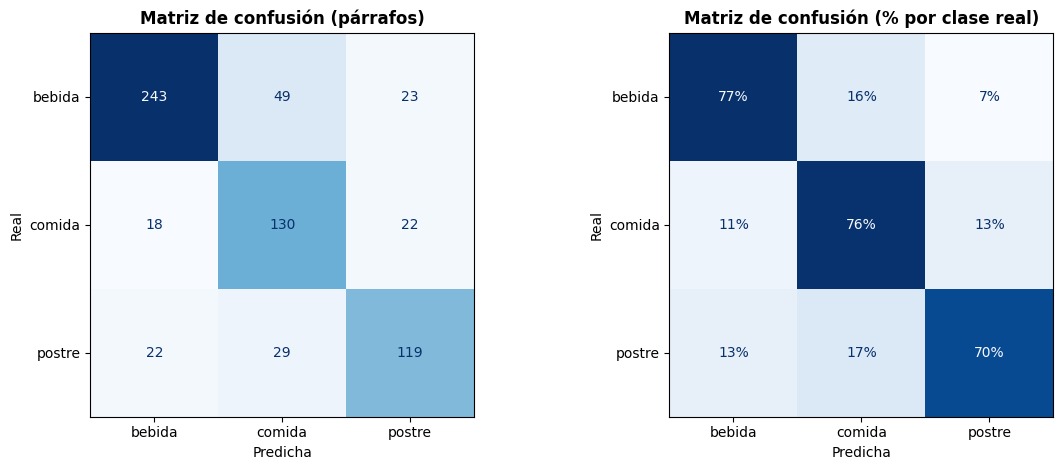

In [15]:
y_pred = modelo_final.predict(X_test)
proba_test = modelo_final.predict_proba(X_test)
acc, f1m = accuracy_score(y_test, y_pred), f1_score(y_test, y_pred, average="macro")

mayoritaria = pd.Series(y_train).mode()[0]
y_base = np.full(len(y_test), mayoritaria)
acc_base, f1_base = accuracy_score(y_test, y_base), f1_score(y_test, y_base, average="macro")

# Intervalo de confianza del F1 macro (bootstrap sobre el conjunto de prueba)
rng = np.random.default_rng(SEMILLA)
boot = []
for _ in range(1000):
    m = rng.integers(0, len(y_test), len(y_test))
    boot.append(f1_score(y_test[m], y_pred[m], average="macro"))
ic_bajo, ic_alto = np.percentile(boot, [2.5, 97.5])

display(pd.DataFrame({"Accuracy": [acc, acc_base], "F1 macro": [f1m, f1_base],
                      "IC 95 % F1": [f"[{ic_bajo:.3f}, {ic_alto:.3f}]", "-"]},
                     index=[f"Modelo final ({MEJOR})", f"Baseline (siempre '{mayoritaria}')"]).round(3))

informe = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T.drop("accuracy")
informe["support"] = informe["support"].astype(int)
display(informe.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASES, cmap="Blues", ax=ejes[0], colorbar=False)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASES, normalize="true", values_format=".0%",
                                        cmap="Blues", ax=ejes[1], colorbar=False)
ejes[0].set_title("Matriz de confusión (párrafos)", fontweight="bold")
ejes[1].set_title("Matriz de confusión (% por clase real)", fontweight="bold")
for eje in ejes:
    eje.set_xlabel("Predicha"); eje.set_ylabel("Real")
plt.tight_layout()
plt.show()

## **10. Análisis del modelo**

### 10.1 Palabras más influyentes de cada clase

En un modelo lineal, cada palabra tiene un peso por clase. Las palabras con más peso son las que más empujan hacia esa clase. Si tienen sentido gastronómico (por ejemplo, `vino` en bebida o `sukero` en postre), el modelo aprende algo razonable y no casualidades.

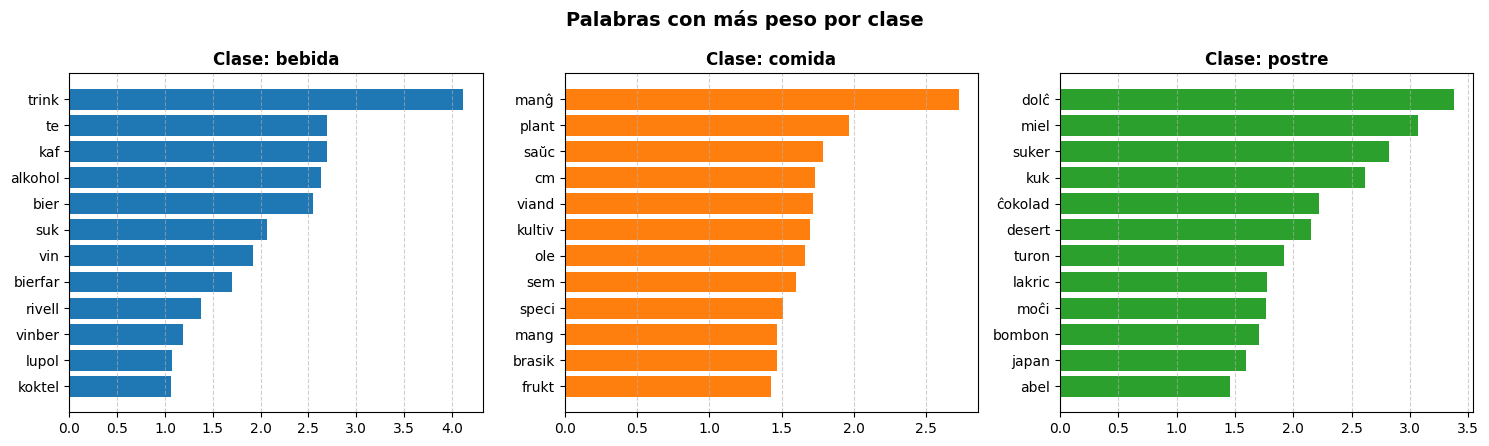

In [16]:
def pesos_por_clase(tuberia):
    # Matriz (clases x palabras) con la importancia de cada palabra, según el tipo de modelo
    clf = tuberia.named_steps["clf"]
    if hasattr(clf, "coef_"):
        W = clf.coef_
    elif hasattr(clf, "feature_log_prob_"):                      # Naive Bayes: log-prob relativa
        W = clf.feature_log_prob_ - clf.feature_log_prob_.mean(axis=0)
    elif hasattr(clf, "calibrated_classifiers_"):                # SVM calibrada: media de las SVM internas
        W = np.mean([getattr(c, "estimator", getattr(c, "base_estimator", None)).coef_
                     for c in clf.calibrated_classifiers_], axis=0)
    else:
        return None
    if W.shape[0] == 1:                                          # caso binario
        W = np.vstack([-W[0], W[0]])
    return np.asarray(W)


W = pesos_por_clase(modelo_final)
terminos = modelo_final.named_steps["tfidf"].get_feature_names_out()
clases_modelo = list(modelo_final.classes_)

if W is not None:
    fig, ejes = plt.subplots(1, len(clases_modelo), figsize=(5 * len(clases_modelo), 4.5))
    for eje, (k, clase) in zip(np.atleast_1d(ejes), enumerate(clases_modelo)):
        top = W[k].argsort()[::-1][:12]
        eje.barh(terminos[top][::-1], W[k][top][::-1], color=COLORES[clase])
        eje.set_title(f"Clase: {clase}", fontweight="bold")
        eje.grid(axis="x", linestyle="--", alpha=0.6)
    plt.suptitle("Palabras con más peso por clase", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 10.2 Ejemplos de aciertos y errores

Para cada ejemplo se muestran las palabras que más han contribuido a la decisión (peso de la palabra × valor TF-IDF en ese párrafo). Así se entiende por qué el modelo acierta o falla.

In [17]:
def explicar(i_test, n=5):
    # Palabras del párrafo que más empujan hacia la clase predicha
    if W is None:
        return ""
    fila = modelo_final.named_steps["tfidf"].transform([X_test[i_test]]).toarray()[0]
    k = clases_modelo.index(y_pred[i_test])
    contrib = fila * W[k]
    top = [j for j in contrib.argsort()[::-1][:n] if contrib[j] > 0]
    return ", ".join(terminos[top])


confianza = proba_test.max(axis=1)
aciertos = np.where(y_pred == y_test)[0]
errores = np.where(y_pred != y_test)[0]


def tabla_ejemplos(posiciones):
    return pd.DataFrame({
        "texto": [df["text"].iloc[idx_test[i]][:140] + "..." for i in posiciones],
        "real": y_test[posiciones], "predicha": y_pred[posiciones],
        "confianza": confianza[posiciones].round(2),
        "palabras decisivas": [explicar(i) for i in posiciones],
    })


print(f"Aciertos: {len(aciertos)} | Errores: {len(errores)}")
print("\nAciertos con más confianza (uno por clase):")
mejores = [aciertos[y_test[aciertos] == c][np.argmax(confianza[aciertos][y_test[aciertos] == c])]
           for c in CLASES if (y_test[aciertos] == c).any()]
display(tabla_ejemplos(mejores))

if len(errores):
    print("Errores con más confianza:")
    display(tabla_ejemplos(errores[np.argsort(-confianza[errores])][:8]))
    print("Confusiones más frecuentes (real -> predicha):")
    display(pd.Series([f"{a} -> {b}" for a, b in zip(y_test[errores], y_pred[errores])]).value_counts().head(5))

Aciertos: 492 | Errores: 163

Aciertos con más confianza (uno por clase):


,texto,real,predicha,confianza,palabras decisivas
0,Espreso (itale espresso) estas trinkaĵo el kaf...,bebida,bebida,0.98,"kaf, trink, akv, prepar, espres"
1,La ĝardena atriplo estas manĝata kiel spinaco ...,comida,comida,0.95,"manĝ, sem, salat, uzat, foli"
2,Miksita kun sukero oni uzas kinako-n en multaj...,postre,postre,0.97,"moĉi, dolĉ, desert, suker, japan"


Errores con más confianza:


,texto,real,predicha,confianza,palabras decisivas
0,"Oni povas aldoni ""lakton kaj mielon"" kun la ra...",bebida,postre,0.90,"miel, dolĉ, suker, abel, rasp"
1,Sabdarifo kreskas kiel unujara herba planto ka...,bebida,comida,0.88,"cm, plant, tig, foli, long"
2,"gusto : de dolĉa al dolĉeta, harmonia, kun bon...",bebida,postre,0.83,"dolĉ, migdal, buŝ, struktur, gust"
3,La floroj staras unuope en la folingoj. La gra...,bebida,comida,0.82,"flor, cm, karn, flav, grand"
4,"Poffertjes estas speco de etaj patkukoj, sed p...",comida,postre,0.77,"patkuk, dolĉ, past, mol, spec"
5,Ĝi povas esti parigita kun fromaĝoj aŭ deserto...,bebida,postre,0.75,"desert, fromaĝ, par"
6,"Balzamvinagro estas eksterordinara vinagro, pr...",comida,bebida,0.74,"alkohol, suk, vinber, far, urb"
7,Sabdarifo (latine Hibiscus sabdariffa) aŭ afri...,bebida,comida,0.73,"plant, speci, azio, famili, malv"


Confusiones más frecuentes (real -> predicha):


,count
bebida -> comida,49
postre -> comida,29
bebida -> postre,23
comida -> postre,22
postre -> bebida,22


### 10.3 Curva de aprendizaje

Se entrena el modelo con porcentajes crecientes del entrenamiento. Si la curva de validación sigue subiendo al final, **más datos mejorarían el modelo**. Si se aplana, el límite está en el ruido de las etiquetas o en lo parecidas que son las clases.

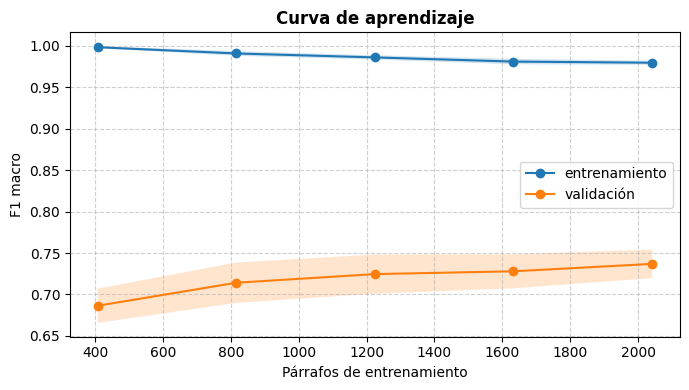

In [18]:
tamanos, sc_train, sc_val = learning_curve(clone(modelo_final), X_train, y_train, groups=g_train, cv=cv,
                                           scoring="f1_macro", train_sizes=np.linspace(0.2, 1.0, 5),
                                           shuffle=True, random_state=SEMILLA)
plt.figure(figsize=(7, 4))
for sc, nombre in [(sc_train, "entrenamiento"), (sc_val, "validación")]:
    plt.plot(tamanos, sc.mean(axis=1), marker="o", label=nombre)
    plt.fill_between(tamanos, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), alpha=0.2)
plt.xlabel("Párrafos de entrenamiento"); plt.ylabel("F1 macro")
plt.title("Curva de aprendizaje", fontweight="bold")
plt.legend(); plt.grid(linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### 10.4 ¿Cuánto infla la nota repartir los párrafos al azar?

Se compara la validación cruzada **por artículos** con una **por párrafos al azar**, usando el mismo modelo y los mismos datos. La diferencia mide la fuga de información que evitamos en el apartado 4.

In [19]:
if g_train is not None:
    azar = StratifiedKFold(n_splits=N_PARTES_CV, shuffle=True, random_state=SEMILLA)
    f1_azar = cross_validate(clone(modelo_final), X_train, y_train, cv=azar, scoring="f1_macro")["test_score"]
    f1_grupo = cross_validate(clone(modelo_final), X_train, y_train, cv=cv, groups=g_train, scoring="f1_macro")["test_score"]
    display(pd.DataFrame({"F1 macro": [f1_azar.mean(), f1_grupo.mean()], "Desv.": [f1_azar.std(), f1_grupo.std()]},
                         index=["Párrafos al azar (optimista)", "Por artículos (realista)"]).round(3))
    print(f"Diferencia: {f1_azar.mean() - f1_grupo.mean():+.3f} de F1 macro")
else:
    print("Sin metadatos de artículo: no se puede hacer esta comparación.")

,F1 macro,Desv.
Párrafos al azar (optimista),0.849,0.015
Por artículos (realista),0.737,0.017


Diferencia: +0.113 de F1 macro


### 10.5 Medición del ruido de las etiquetas

Se predice **cada párrafo del dataset** con un modelo que no lo ha visto (`cross_val_predict`) y se clasifican en tres grupos:

- **Coincide con el modelo:** el modelo predice la misma clase; **no prueba** que la etiqueta sea correcta.
- **Desacuerdo flojo:** el modelo no coincide, pero duda.
- **Posible etiqueta dudosa:** el modelo contradice la etiqueta con confianza ≥ 0,8.

El último grupo es una **señal exploratoria** de posibles etiquetas ruidosas, no una medición de errores de etiquetado confirmados manualmente. Muchos de esos párrafos hablan de otro tema dentro del artículo, por ejemplo un párrafo sobre vino dentro de un artículo de comida.

grupo,Coincide con el modelo,Desacuerdo flojo,Posible etiqueta dudosa
clase,,,
bebida,80.4,18.6,1.0
comida,75.2,24.2,0.6
postre,68.5,30.8,0.8


Posibles etiquetas dudosas: 25 de 3152 párrafos (0.8%)


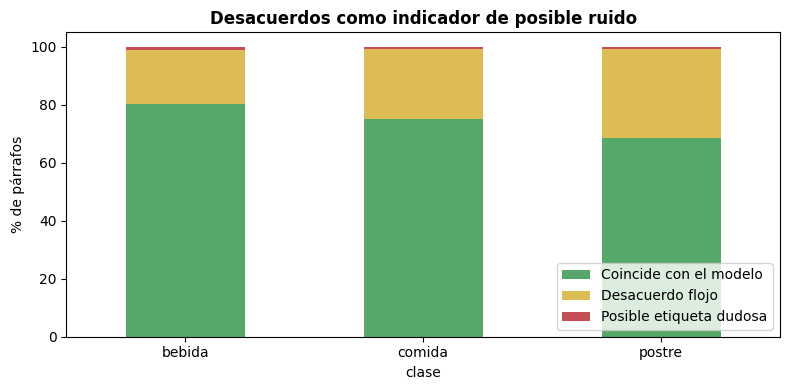

,texto,etiqueta,modelo,confianza
0,"Laktoskuaĵo aŭ laktokirlaĵo estas dolĉa, malva...",bebida,postre,0.96
1,produktado de etanolo kaj alkoholaĵoj per ferm...,comida,bebida,0.93
2,Ovobrando ankaŭ estas uzata en glaciaĵo aŭ kuk...,bebida,postre,0.93
3,En la kuirarto oni uzas bieron ankaŭ por fajni...,bebida,comida,0.93
4,Varma ĉokolado (aŭ trinkĉokolado) estas prepar...,bebida,postre,0.92
5,Alkohola mikstrinkaĵo el vodko kaj Red Bull es...,postre,bebida,0.92


In [20]:
cv_ruido = (StratifiedGroupKFold(n_splits=N_PARTES_CV, shuffle=True, random_state=SEMILLA) if grupos is not None
            else StratifiedKFold(n_splits=N_PARTES_CV, shuffle=True, random_state=SEMILLA))
probas_cv = cross_val_predict(clone(modelo_final), textos_finales, y, cv=cv_ruido, groups=grupos, method="predict_proba")
pred_cv = np.array(clases_modelo)[probas_cv.argmax(axis=1)]
conf_cv = probas_cv.max(axis=1)

UMBRAL = 0.8
grupo_ruido = np.where(pred_cv == y, "Coincide con el modelo",
                       np.where(conf_cv >= UMBRAL, "Posible etiqueta dudosa", "Desacuerdo flojo"))
orden = ["Coincide con el modelo", "Desacuerdo flojo", "Posible etiqueta dudosa"]
ruido = (pd.crosstab(pd.Series(y, name="clase"), pd.Series(grupo_ruido, name="grupo"), normalize="index") * 100)
ruido = ruido.reindex(columns=orden, fill_value=0)
display(ruido.round(1))

n_dudosos = int((grupo_ruido == "Posible etiqueta dudosa").sum())
print(f"Posibles etiquetas dudosas: {n_dudosos} de {len(y)} párrafos ({n_dudosos / len(y):.1%})")

ruido.plot(kind="bar", stacked=True, figsize=(8, 4), color=["#55A868", "#DDBB55", "#C44E52"], rot=0)
plt.title("Desacuerdos como indicador de posible ruido", fontweight="bold")
plt.ylabel("% de párrafos"); plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

dudosos = np.where(grupo_ruido == "Posible etiqueta dudosa")[0]
if len(dudosos):
    top = dudosos[np.argsort(-conf_cv[dudosos])][:6]
    display(pd.DataFrame({"texto": df["text"].iloc[top].str[:150] + "...", "etiqueta": y[top],
                          "modelo": pred_cv[top], "confianza": conf_cv[top].round(2)}).reset_index(drop=True))

## **11. Clasificación de páginas web reales (web scraping)**

Se descargan páginas en Esperanto con `requests` y se extraen párrafos mediante `BeautifulSoup`, eliminando menús, referencias y ruido. Cada párrafo se prepara con el mismo NLP que el entrenamiento. Para cada página se muestran las probabilidades medias de `comida`, `bebida` y `postre`.

- Los artículos utilizados para esta evaluación web están en la lista de reservados de la Fase 1 y se comprueba su ausencia del entrenamiento.
- Si una página falla, se salta sin interrumpir el cuaderno.
- **Si todas las páginas reales fallan, no se simula una evaluación web.** Se muestra aparte una demostración con textos escritos para comprobar el código, que **no cuenta como prueba web real**. Debe repetirse la ejecución con conexión antes de entregar.


In [21]:
# (nombre, URL, categoría esperada). Reservadas en el script del dataset: nunca se entrenó con ellas.
PAGINAS_WEB = [
    ("Kolbaso", "https://eo.wikipedia.org/wiki/Kolbaso", "comida"),
    ("Hamburgero", "https://eo.wikipedia.org/wiki/Hamburgero", "comida"),
    ("Sandviĉo", "https://eo.wikipedia.org/wiki/Sandvi%C4%89o", "comida"),
    ("Viskio", "https://eo.wikipedia.org/wiki/Viskio", "bebida"),
    ("Vodko", "https://eo.wikipedia.org/wiki/Vodko", "bebida"),
    ("Rumo", "https://eo.wikipedia.org/wiki/Rumo", "bebida"),
    ("Baklavo", "https://eo.wikipedia.org/wiki/Baklavo", "postre"),
    ("Tiramisuo", "https://eo.wikipedia.org/wiki/Tiramisuo", "postre"),
    ("Karamelo", "https://eo.wikipedia.org/wiki/Karamelo", "postre"),
]

# Páginas mixtas, sin una categoría esperada. Incluye una web que no es Wikipedia (Vikilibroj).
PAGINAS_MIXTAS = [
    ("Itala kuirarto (Vikipedio)", "https://eo.wikipedia.org/wiki/Itala_kuirarto"),
    ("Hispana kuirarto (Vikipedio)", "https://eo.wikipedia.org/wiki/Hispana_kuirarto"),
    ("Kuirlibro (Vikilibroj)", "https://eo.wikibooks.org/wiki/Kuirlibro"),
]
URL_PERSONALIZADA = ""            # cualquier otra página en Esperanto (vacío = no se usa)

# Segunda barrera contra fuga de información: detectar títulos reservados que
# podrían haberse introducido accidentalmente en el CSV al cambiar la configuración.
if df["article"].notna().all():
    articulos_entrenados = set(df["article"].astype(str).str.casefold())
    filtrados = [nombre for nombre, _, _ in PAGINAS_WEB
                 if nombre.casefold() in articulos_entrenados]
    if filtrados:
        raise RuntimeError(f"Las páginas reservadas aparecen en el dataset: {filtrados}. "
                           "Exclúyelas de la Fase 1, regenera el CSV y reentrena el modelo.")

MIN_PARRAFOS = 2                  # mínimo de párrafos útiles para tener en cuenta una página
MIN_RATIO_ESPERANTO = 0.6         # mismo umbral que en el script del dataset

# EJEMPLOS ILUSTRATIVOS escritos por el equipo: no son resultados de scraping web.
TEXTOS_RESPALDO = [
    ("Pico (respaldo)", "comida", "La pico estas itala manĝaĵo el pasto, tomata saŭco kaj fromaĝo, bakita en forno.\n"
                                  "Ni kuiras supon el legomoj kaj manĝas ĝin kun pano kaj fiŝo."),
    ("Biero (respaldo)", "bebida", "La biero estas alkohola trinkaĵo farita el hordeo, akvo kaj lupolo.\n"
                                   "Oni trinkas kafon kaj teon varme aŭ malvarme en glaso."),
    ("Kuko (respaldo)", "postre", "La kuko estas dolĉa deserto el faruno, sukero, ovoj kaj butero.\n"
                                  "La glaciaĵo kaj la pudingo estas dolĉaĵoj kiujn infanoj tre ŝatas."),
]

In [22]:
CABECERAS = {"User-Agent": "Mozilla/5.0 (compatible; PracticaMineriaTextos/1.0)"}


def descargar_html(url, intentos=1, espera=0):
    # Descarga una página con reintentos. Nunca lanza errores: devuelve None si falla.
    for intento in range(1, intentos + 1):
        try:
            r = requests.get(url, headers=CABECERAS, timeout=8)
            if r.status_code == 404:
                print(f"   404, la página no existe: {url}")
                return None
            r.raise_for_status()
            return r.content
        except requests.RequestException as error:
            print(f"   Intento {intento}/{intentos} fallido ({type(error).__name__})")
            time.sleep(espera)
    return None


def extraer_parrafos(html):
    # Extrae párrafos en Esperanto del HTML de cualquier web
    soup = BeautifulSoup(html, "html.parser")
    for etiqueta in soup(["script", "style", "sup", "table", "nav", "footer", "header", "aside", "form"]):
        etiqueta.decompose()
    zona = (soup.select_one("#mw-content-text") or soup.find("article") or soup.find("main")
            or soup.body or soup)

    def limpiar(elementos):
        salida = []
        for e in elementos:
            texto = " ".join(e.get_text(" ", strip=True).replace(";", ",").split())
            if len(texto) >= 30 and nlp(texto).esperanto_ratio() >= MIN_RATIO_ESPERANTO:
                salida.append(texto)
        return salida

    parrafos = limpiar(zona.find_all("p"))
    if len(parrafos) < MIN_PARRAFOS:                  # webs de recetas: el texto suele ir en listas
        parrafos += limpiar(zona.find_all("li"))
    return parrafos


def cargar_pagina(nombre, url):
    html = descargar_html(url)
    if html is None:
        print(f"✗ {nombre}: no se pudo descargar")
        return None
    parrafos = extraer_parrafos(html)
    if len(parrafos) < MIN_PARRAFOS:
        print(f"✗ {nombre}: solo {len(parrafos)} párrafos útiles (se descarta)")
        return None
    print(f"✓ {nombre}: {len(parrafos)} párrafos")
    return parrafos


def preparar(texto):
    # Mismo proceso que en el entrenamiento
    return " ".join(nlp(texto).words(ATRIBUTOS.get(VERSION_ELEGIDA, "lemma_"), min_len=2, alpha_only=True))


def clasificar_pagina(parrafos):
    # Devuelve (probabilidad media por clase, tabla por párrafo) o None si no hay texto útil
    preparados = [preparar(p) for p in parrafos]
    utiles = [(p, t) for p, t in zip(parrafos, preparados) if t.strip()]
    if not utiles:
        return None
    probas = modelo_final.predict_proba([t for _, t in utiles])
    tabla = pd.DataFrame(probas, columns=clases_modelo)
    tabla.insert(0, "texto", [p for p, _ in utiles])
    tabla["predicha"] = tabla[clases_modelo].idxmax(axis=1)
    tabla["confianza"] = tabla[clases_modelo].max(axis=1)
    return tabla[clases_modelo].mean(), tabla

Descargando páginas...
✓ Kolbaso: 3 párrafos
✓ Hamburgero: 5 párrafos
✓ Sandviĉo: 2 párrafos
✓ Viskio: 6 párrafos
✓ Vodko: 6 párrafos
✓ Rumo: 4 párrafos
✓ Baklavo: 9 párrafos
✓ Tiramisuo: 7 párrafos
✓ Karamelo: 3 párrafos


,Página,Esperada,Predicha,P(bebida),P(comida),P(postre),Párrafos,Acierto
0,Kolbaso,comida,comida,0.151,0.614,0.235,3,sí
1,Hamburgero,comida,comida,0.207,0.564,0.230,5,sí
2,Sandviĉo,comida,comida,0.183,0.555,0.262,2,sí
3,Viskio,bebida,bebida,0.710,0.139,0.151,6,sí
4,Vodko,bebida,bebida,0.540,0.271,0.189,6,sí
5,Rumo,bebida,bebida,0.683,0.178,0.139,4,sí
6,Baklavo,postre,postre,0.186,0.278,0.537,9,sí
7,Tiramisuo,postre,bebida,0.514,0.148,0.339,7,no
8,Karamelo,postre,postre,0.111,0.127,0.762,3,sí


Páginas bien clasificadas: 8 de 9


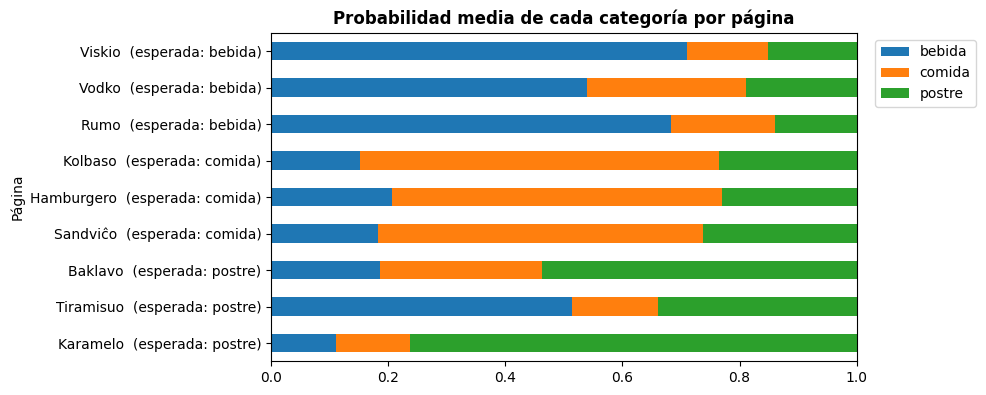

In [23]:
print("Descargando páginas...")
resultados = []
for nombre, url, esperada in PAGINAS_WEB:
    parrafos = cargar_pagina(nombre, url)
    res = clasificar_pagina(parrafos) if parrafos else None
    if res is None:
        continue
    medias, _ = res
    resultados.append({"Página": nombre, "Esperada": esperada, "Predicha": medias.idxmax(),
                       **{f"P({c})": medias[c] for c in clases_modelo}, "Párrafos": len(parrafos)})

if not resultados:
    print("No hay páginas REALES descargadas. Lo siguiente es una DEMOSTRACIÓN LOCAL, "
          "no una evaluación de web scraping.")
    demostracion = []
    for nombre, esperada, texto in TEXTOS_RESPALDO:
        if esperada not in clases_modelo:
            continue
        res = clasificar_pagina(texto.split("\n"))
        if res is not None:
            medias, _ = res
            demostracion.append({"Ejemplo ilustrativo": nombre, "Esperada": esperada,
                                 "Predicha": medias.idxmax(), **{f"P({c})": medias[c] for c in clases_modelo}})
    if demostracion:
        display(pd.DataFrame(demostracion).round(3))

tabla_web = pd.DataFrame(resultados)
if len(tabla_web):
    tabla_web["Acierto"] = np.where(tabla_web["Esperada"] == tabla_web["Predicha"], "sí", "no")
    display(tabla_web.round(3))
    aciertos_web = int((tabla_web["Acierto"] == "sí").sum())
    print(f"Páginas bien clasificadas: {aciertos_web} de {len(tabla_web)}")

    probs = tabla_web.sort_values("Esperada").set_index("Página")[[f"P({c})" for c in clases_modelo]]
    probs.columns = clases_modelo
    etiquetas = tabla_web.set_index("Página")["Esperada"]
    ax = probs.plot(kind="barh", stacked=True, figsize=(10, max(3, 0.45 * len(probs))),
                    color=[COLORES.get(c) for c in clases_modelo])
    ax.set_yticklabels([f"{p}  (esperada: {etiquetas[p]})" for p in probs.index])
    ax.set_xlim(0, 1); ax.invert_yaxis()
    ax.set_title("Probabilidad media de cada categoría por página", fontweight="bold")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    aciertos_web = None
    print("No se ha podido clasificar ninguna página REAL: la Fase 3 web está pendiente de verificación con conexión.")

✓ Itala kuirarto (Vikipedio): 18 párrafos
✓ Hispana kuirarto (Vikipedio): 3 párrafos
✗ Kuirlibro (Vikilibroj): solo 0 párrafos útiles (se descarta)


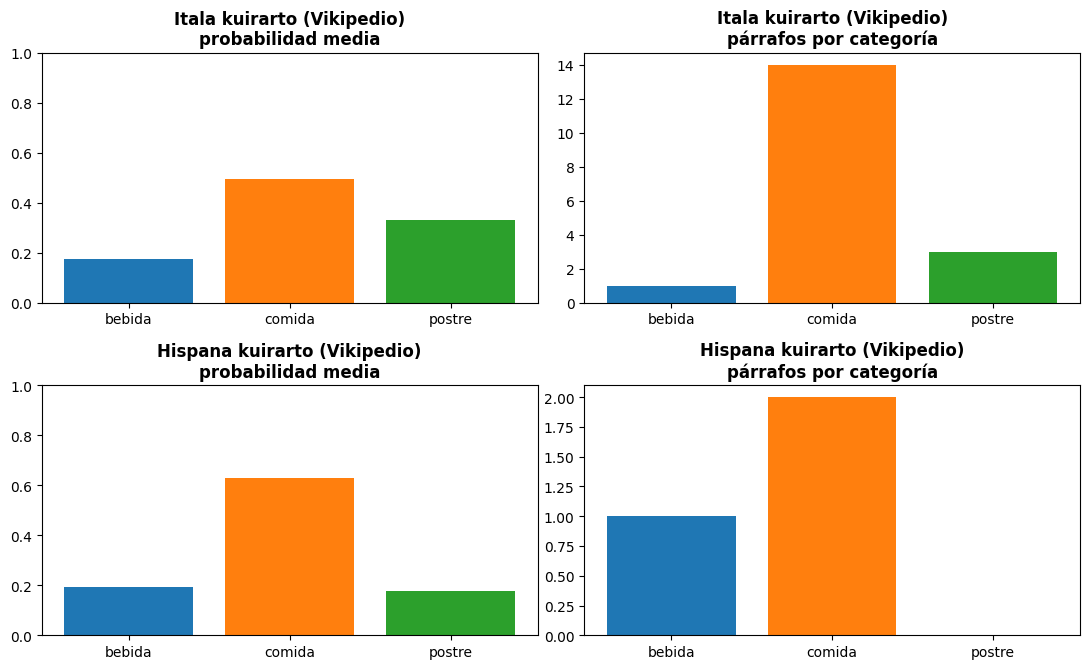


Itala kuirarto (Vikipedio): primeros párrafos


,texto,predicha,confianza
0,La itala kuirarto estas unu el ĉefaj internaci...,comida,0.69
1,La itala kuirarto karakteriziĝas pro la uzo de...,comida,0.83
2,"La itala pico estas fama dismonde, ĝi evoluis ...",comida,0.43
3,Focaccia ([foˈkattʃa] do en Esperanto fokaĉo )...,comida,0.52
4,En Italio la ĉefa manĝada tempo estas la vespe...,comida,0.44



Hispana kuirarto (Vikipedio): primeros párrafos


,texto,predicha,confianza
0,Estas malfacile paroli pri tipe hispana kuirar...,comida,0.75
1,En Hispanio oni manĝas pli poste ol ekzemple e...,bebida,0.39
2,Sekigu kaj poste tranĉu ĝin por friti en la ol...,comida,0.76


In [24]:
paginas_extra = list(PAGINAS_MIXTAS) + ([("Página personalizada", URL_PERSONALIZADA)] if URL_PERSONALIZADA else [])
detalle = {}
for nombre, url in paginas_extra:
    parrafos = cargar_pagina(nombre, url)
    res = clasificar_pagina(parrafos) if parrafos else None
    if res is not None:
        detalle[nombre] = res

if not detalle:
    print("No se pudo cargar ninguna página mixta (se sigue con el resto del cuaderno).")
else:
    fig, ejes = plt.subplots(len(detalle), 2, figsize=(11, 3.4 * len(detalle)), squeeze=False)
    for fila, (nombre, (medias, tabla)) in zip(ejes, detalle.items()):
        colores = [COLORES.get(c) for c in clases_modelo]
        fila[0].bar(clases_modelo, [medias[c] for c in clases_modelo], color=colores)
        fila[0].set_ylim(0, 1); fila[0].set_title(f"{nombre}\nprobabilidad media", fontweight="bold")
        n = tabla["predicha"].value_counts().reindex(clases_modelo, fill_value=0)
        fila[1].bar(clases_modelo, n.values, color=colores)
        fila[1].set_title(f"{nombre}\npárrafos por categoría", fontweight="bold")
    plt.tight_layout()
    plt.show()
    for nombre, (_, tabla) in detalle.items():
        print(f"\n{nombre}: primeros párrafos")
        t = tabla[["texto", "predicha", "confianza"]].head(5).copy()
        t["texto"] = t["texto"].str[:140] + "..."
        display(t.round(2))

## **12. Conclusiones**

El resumen se genera con los resultados de esta ejecución, así que siempre coincide con las cifras de arriba.

In [25]:
resumen = pd.DataFrame({"Valor": {
    "Párrafos / clases": f"{len(df)} / {len(CLASES)}",
    "Partición": "por artículos" if grupos is not None else "por párrafos",
    "Preparación elegida": VERSION_ELEGIDA,
    "Mejora frente al texto original (F1, CV)": f"{mejora:+.3f}",
    "Modelo": f"{MEJOR} {busqueda.best_params_}",
    "Accuracy en prueba": f"{acc:.3f}",
    "F1 macro en prueba (IC 95 %)": f"{f1m:.3f} [{ic_bajo:.3f}, {ic_alto:.3f}]",
    "F1 macro del baseline": f"{f1_base:.3f}",
    "Desacuerdos de alta confianza (no revisados)": f"{n_dudosos} ({n_dudosos / len(y):.1%})",
    "Páginas web bien clasificadas": (f"{aciertos_web} de {len(tabla_web)}" if aciertos_web is not None
                                      else "Pendiente: no se descargaron páginas reales"),
    "Tiempo total del cuaderno": f"{time.time() - inicio_cuaderno:.0f} s",
}})
display(resumen)

f1_clase = informe.loc[CLASES, "f1-score"]
display(Markdown(
    f"- El modelo final (**{MEJOR}**) obtiene un **F1 macro de {f1m:.3f}** en prueba, frente a {f1_base:.3f} del baseline.\n"
    f"- La clase más fácil es **{f1_clase.idxmax()}** (F1 {f1_clase.max():.2f}) y la más difícil es **{f1_clase.idxmin()}** "
    f"(F1 {f1_clase.min():.2f}).\n"
    f"- Usar `eonlp` ({VERSION_ELEGIDA[3:].lower()}) cambia el F1 en {mejora:+.3f} respecto al texto sin procesar.\n"
    f"- El {n_dudosos / len(y):.0%} de los párrafos presentan desacuerdo de alta confianza con la etiqueta. "
    f"Esto **no demuestra** que las etiquetas sean incorrectas: se necesitaría revisión manual."
))

,Valor
Párrafos / clases,3152 / 3
Partición,por artículos
Preparación elegida,D) Raíces sin stopwords
"Mejora frente al texto original (F1, CV)",+0.054
Modelo,"Regresión logística {'clf__C': 1, 'tfidf__min_..."
Accuracy en prueba,0.751
F1 macro en prueba (IC 95 %),"0.738 [0.703, 0.774]"
F1 macro del baseline,0.137
Desacuerdos de alta confianza (no revisados),25 (0.8%)
Páginas web bien clasificadas,8 de 9


- El modelo final (**Regresión logística**) obtiene un **F1 macro de 0.738** en prueba, frente a 0.137 del baseline.
- La clase más fácil es **bebida** (F1 0.81) y la más difícil es **comida** (F1 0.69).
- Usar `eonlp` (raíces sin stopwords) cambia el F1 en +0.054 respecto al texto sin procesar.
- El 1% de los párrafos presentan desacuerdo de alta confianza con la etiqueta. Esto **no demuestra** que las etiquetas sean incorrectas: se necesitaría revisión manual.

**Qué hemos aprendido**

- La regularidad del Esperanto permite construir con reglas un lematizador y un etiquetador basados en reglas, con limitaciones conocidas. Agrupar las formas de una palabra reduce el vocabulario y ayuda al clasificador (apartado 5).
- Evaluar bien importa tanto como el modelo. Repartir párrafos de un mismo artículo entre entrenamiento y prueba infla la nota (apartado 10.4), así que la partición por artículos da una estimación más honesta.
- El F1 macro, la matriz de confusión y los ejemplos explicados muestran *dónde* y *por qué* falla el modelo, cosa que la accuracy sola no enseña.

**Limitaciones**

- **Ruido de etiquetas:** cada párrafo hereda la etiqueta del artículo. Se han medido desacuerdos entre etiquetas y predicciones (apartado 10.5), sin revisión humana suficiente para cuantificar errores reales.
- **Clases cercanas:** muchos textos de postres hablan de ingredientes (azúcar, harina, huevos) que también son comida. Es la confusión esperable.
- **Reglas de la librería:** los falsos participios y los nombres extranjeros dependen de listas de excepciones que no pueden ser completas. Están documentados en el repositorio.
- **Páginas web:** la categoría esperada es un criterio nuestro y algunas páginas tratan varios temas.

**Posibles mejoras**

- Revisar a mano los párrafos marcados como dudosos y reetiquetarlos o eliminarlos.
- Añadir más artículos por clase si la curva de aprendizaje (10.3) sigue subiendo.
- Probar n-gramas de caracteres, que capturan sufijos y raíces sin necesidad de reglas.